# Le rail suit-il la France qui grandit ?

Analyse descriptive de données publiques : population, gares et mobilités. Comparaison principale **2016–2022**, contexte SNCF **2015–2024**. Aucun chiffre simulé ni imputation aléatoire.

Ce notebook part des archives locales brutes et reconstruit les tables, figures et contrôles. Il fonctionne hors ligne une fois les sources collectées. Les méthodes, hypothèses, exceptions et limites sont expliquées dans [la méthodologie](docs/METHODOLOGIE.md) et les colonnes dans [le dictionnaire](docs/DICTIONNAIRE_DONNEES.md).

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd()
if not (ROOT / 'run.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'run.py').is_file(), 'Ouvrir le notebook à la racine du projet'
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))

# True : reconstruction depuis les fichiers bruts (comportement de restitution).
# False : lecture des tables déjà produites, pour une exploration rapide.
DEPUIS_LES_BRUTS = True
from run import execute
from src.validation import run as valider
validation = execute(documents=False) if DEPUIS_LES_BRUTS else valider()
assert validation['statut'] == 'CONFORME'
print(f"Validation : {validation['nombre_controles']} contrôles, {validation['nombre_echecs']} échec.")

KeyboardInterrupt: 

## 1. Population statistique et qualité des jointures

Les tables gardent leurs grains : une commune dans la table finale, un UIC × année dans le panel ferroviaire. Les comptages des gares ne sont pas des voyages uniques. Le champ démographique est le COG2025, hors Mayotte ; l'analyse territoriale principale est métropolitaine.

In [4]:
import json
import pandas as pd
from IPython.display import display, Image, Markdown
communes = pd.read_parquet('data/processed/dataset_final_communes.parquet')
gares = pd.read_parquet('data/processed/gares_annees.parquet')
qualite = json.loads(Path('outputs/tables/qualite_jointures.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'communes': len(communes), 'UIC': gares.code_uic.nunique(),
                      'observations_UIC_annee': len(gares),
                      'jointure_commune_pct': qualite['taux_jointure_commune_pct']}]))
assert not communes.code_commune.duplicated().any()
assert not gares.duplicated(['code_uic', 'annee']).any()
display(pd.read_csv('outputs/tables/gares_jointure_incomplete.csv', dtype={'code_uic': str}))

NameError: name 'Path' is not defined

## 2. Trajectoires démographiques

On distingue taux annuels communaux, croissance agrégée et soldes naturel/migratoire apparent. Une moyenne de taux communaux n'est pas la croissance de la population totale. Les couleurs des cartes sont saturées aux seuils annoncés ; les tables conservent toutes les valeurs.

,annee,population
0,1968,49711853
1,1975,52591584
2,1982,54334871
3,1990,56615155
4,1999,58518395
5,2006,61399733
6,2011,63070344
7,2016,64468792
8,2022,65846255


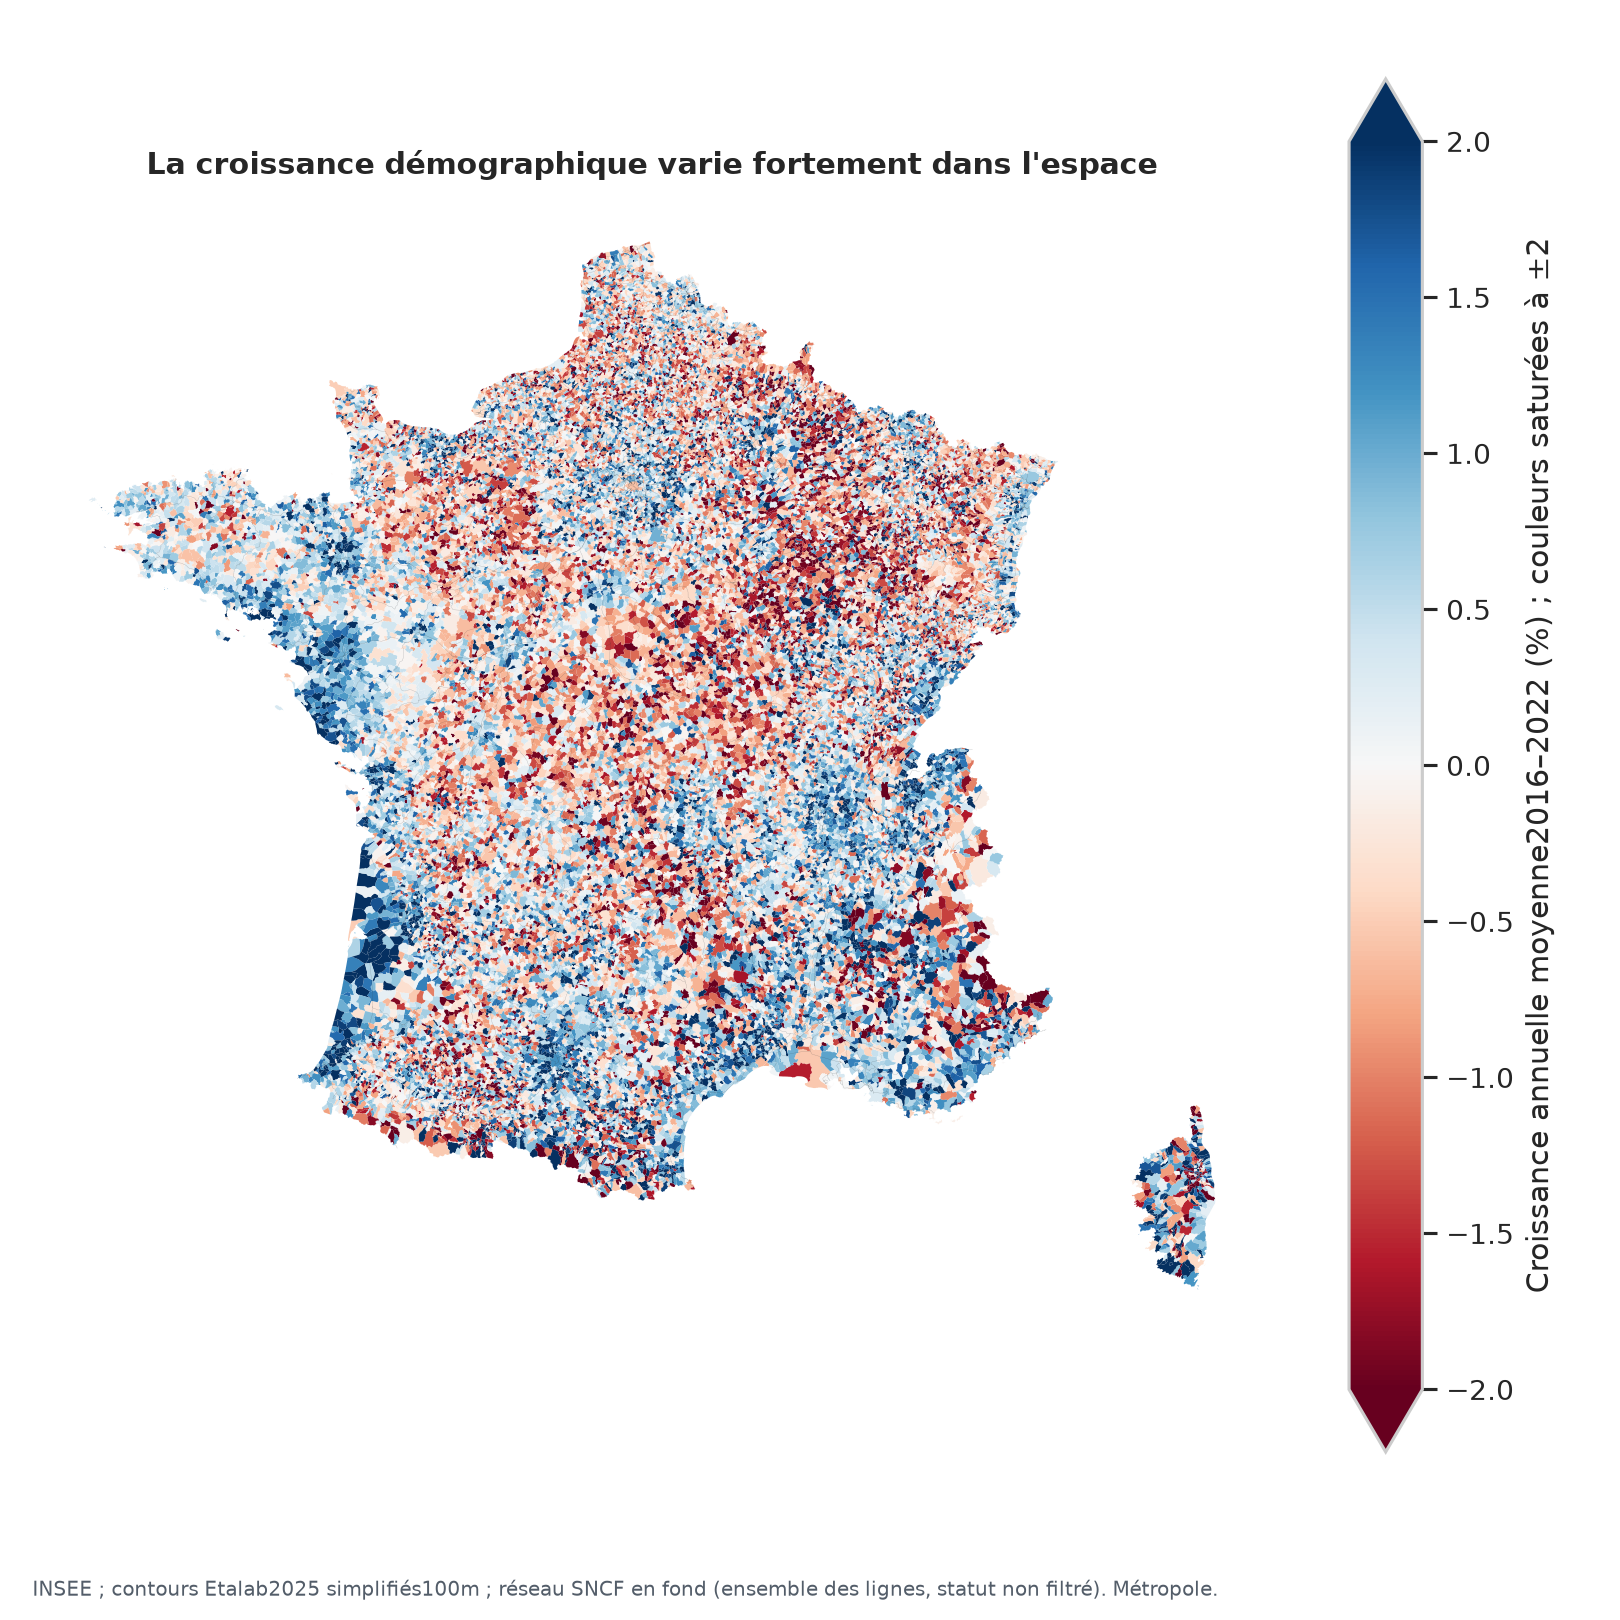

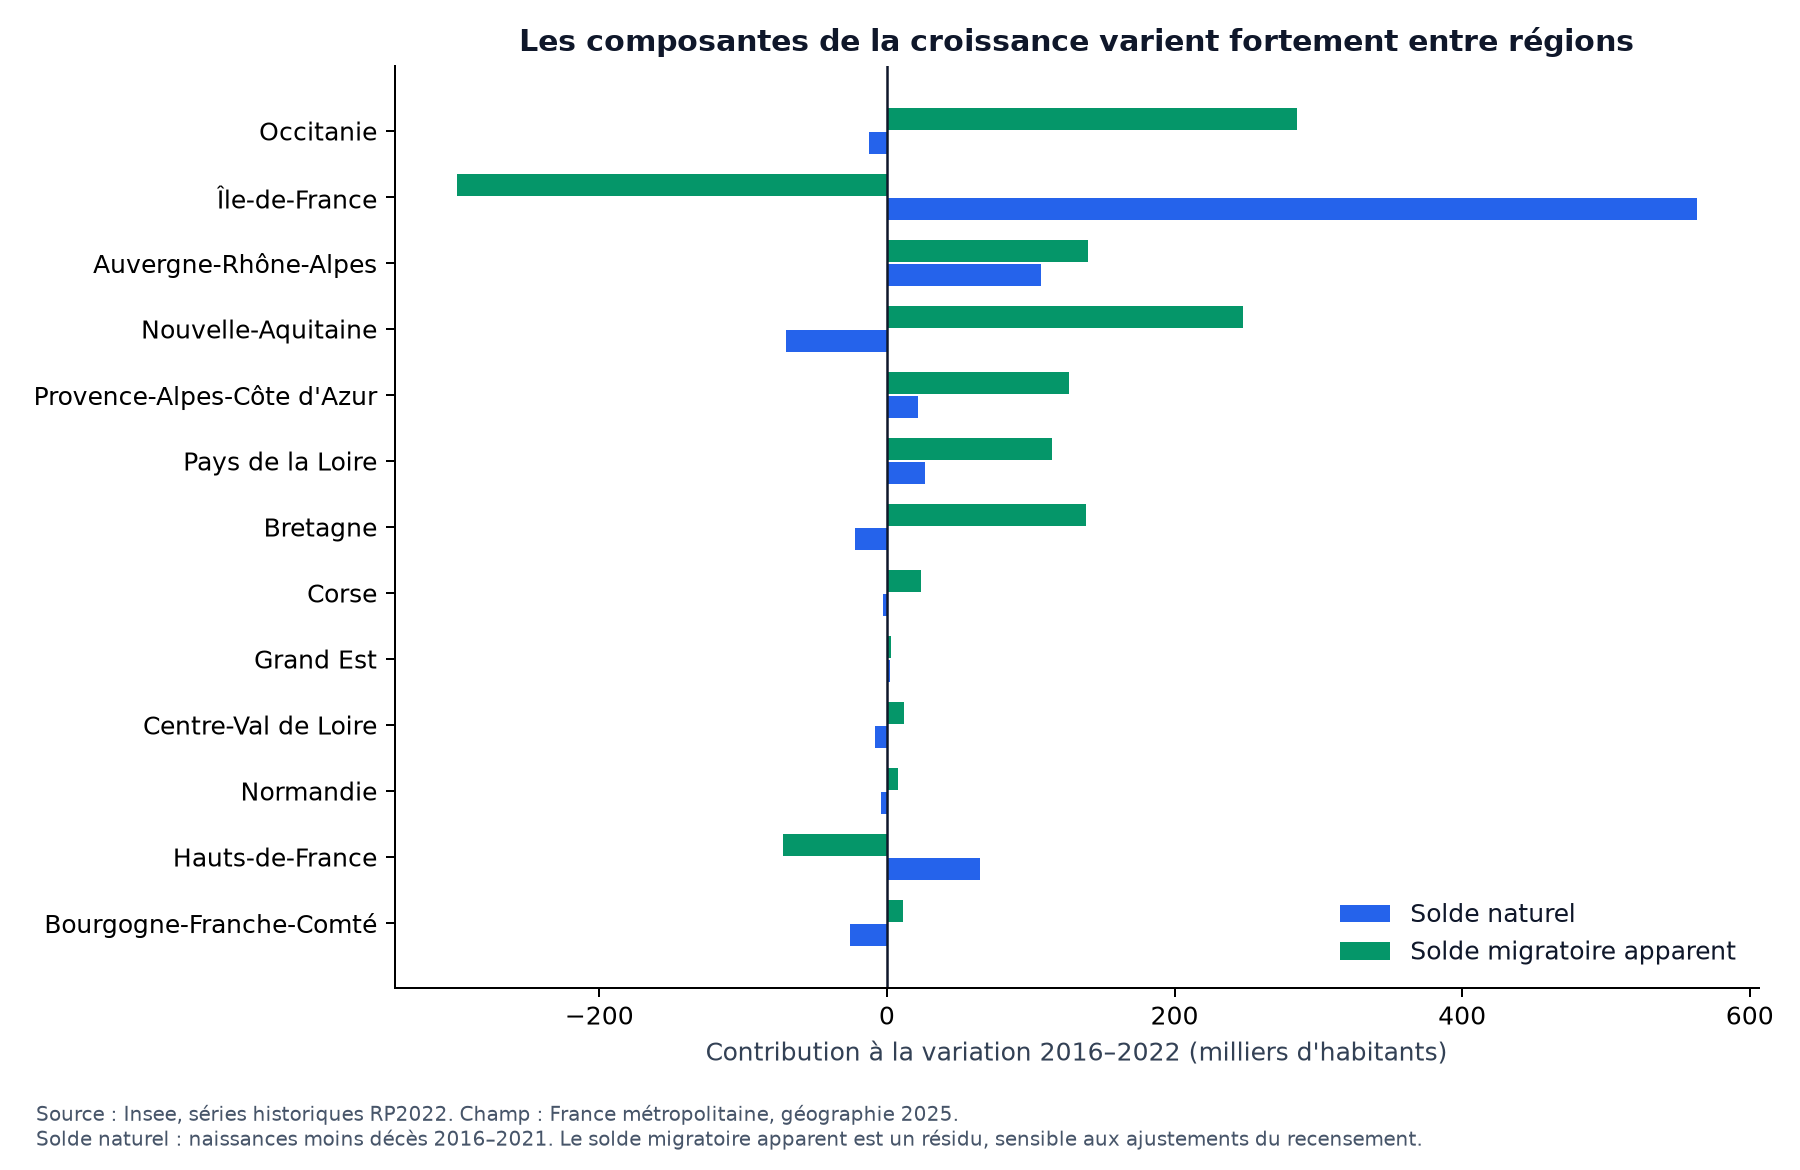

In [3]:
display(pd.read_csv('outputs/demographie/population_metropole_historique.csv'))
display(Image(filename='outputs/figures/07_carte_demographie.png', width=850))
display(Image(filename='outputs/demographie/03_soldes_regions.png', width=850))

## 3. Concentration, Covid et reprise des comptages

La concentration impose de regarder médiane, quantiles et Lorenz/Gini. Les zéros publiés sont conservés et ne prouvent pas une fermeture. L'indice base100en2019 distingue le choc Covid de la reprise. Le périmètre SNCF est non exhaustif et l'historique révisable.

,annee,comptages_voyageurs,nb_gares,nb_observations_valides,nb_gares_positives,mediane_comptages,indice_base100_2019,indice_cohorte_complete_base100_2019
0,2015,2621371521,3021,3021,2960,42046.0,95.919463,95.917893
1,2016,2650891274,3021,3021,2963,41023.0,96.999630,96.998239
2,2017,2731725717,3021,3021,2965,43087.0,99.957470,99.956520
3,2018,2682741092,3021,3021,2963,39646.0,98.165057,98.164676
4,2019,2732888017,3021,3021,2953,44042.0,100.000000,100.000000
5,2020,1428835200,3021,3021,2939,30059.0,52.282977,52.282923
6,2021,2074413159,3021,3021,2917,37979.0,75.905531,75.905228
7,2022,2598819834,3021,3021,2940,51748.0,95.094267,95.053359
8,2023,2789110073,3021,3021,2936,57877.0,102.057240,101.965947
9,2024,3068305604,3021,3021,2925,63510.0,112.273375,111.624880


,quantile,comptages_voyageurs_2024
0,0.00,0.0
1,0.10,1525.0
2,0.25,12080.0
3,0.50,63510.0
4,0.75,308109.0
5,0.90,1632269.0
6,0.99,17160570.0
7,1.00,257024152.0


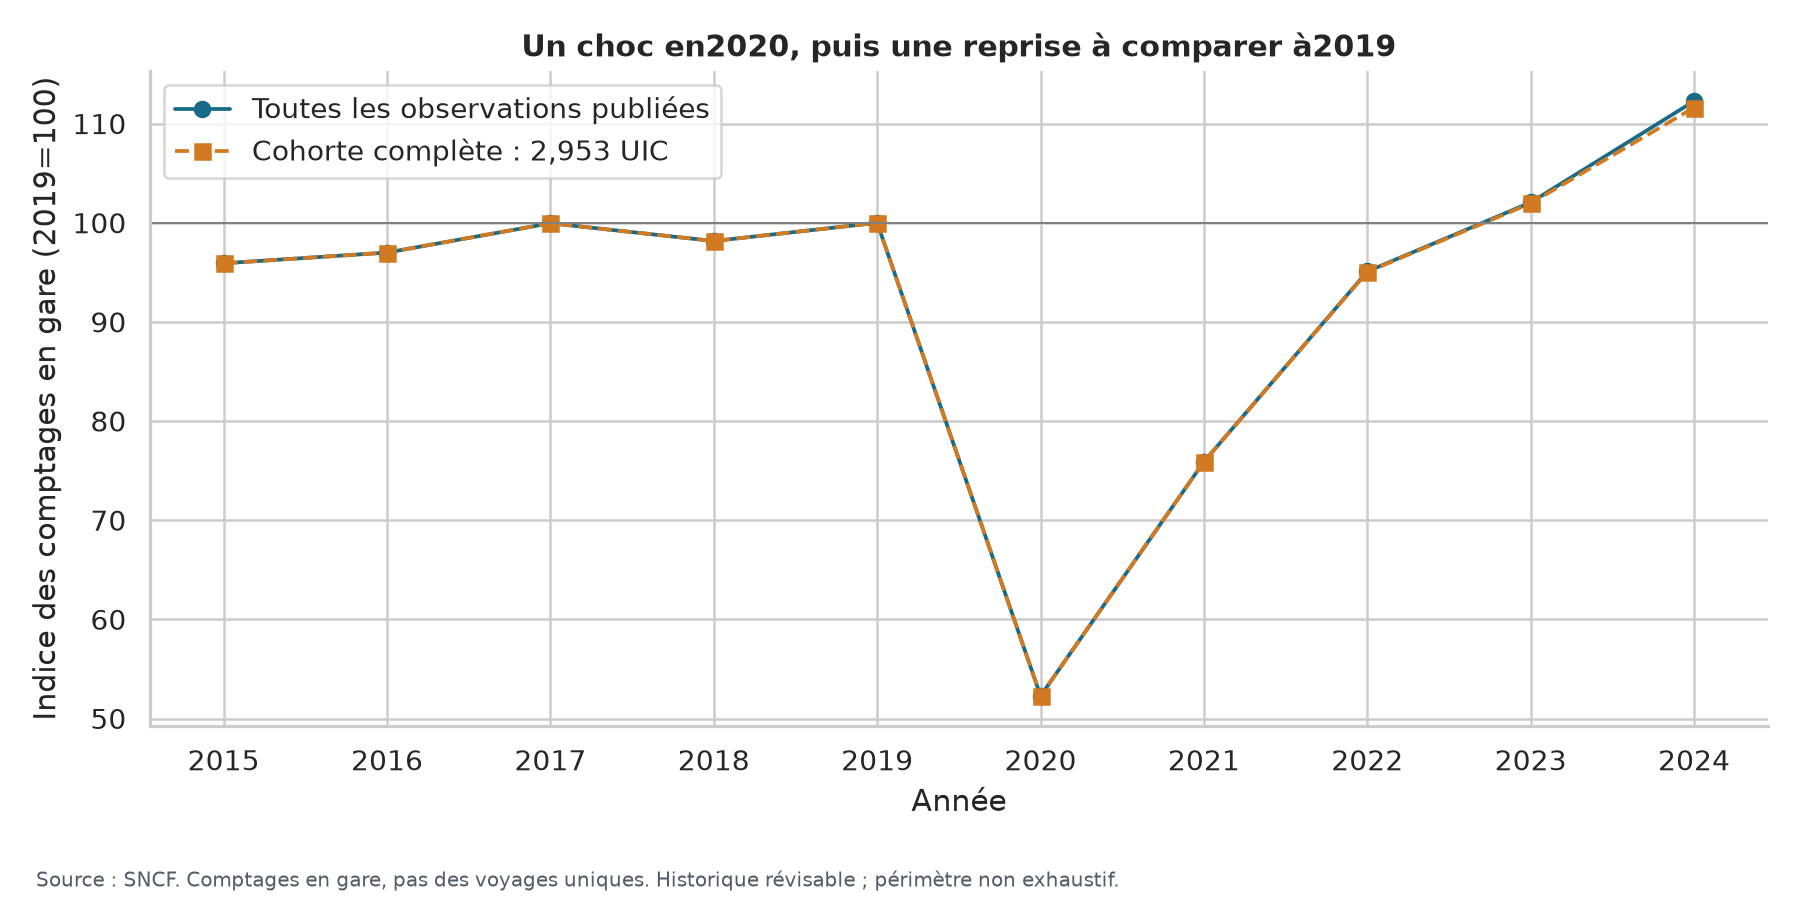

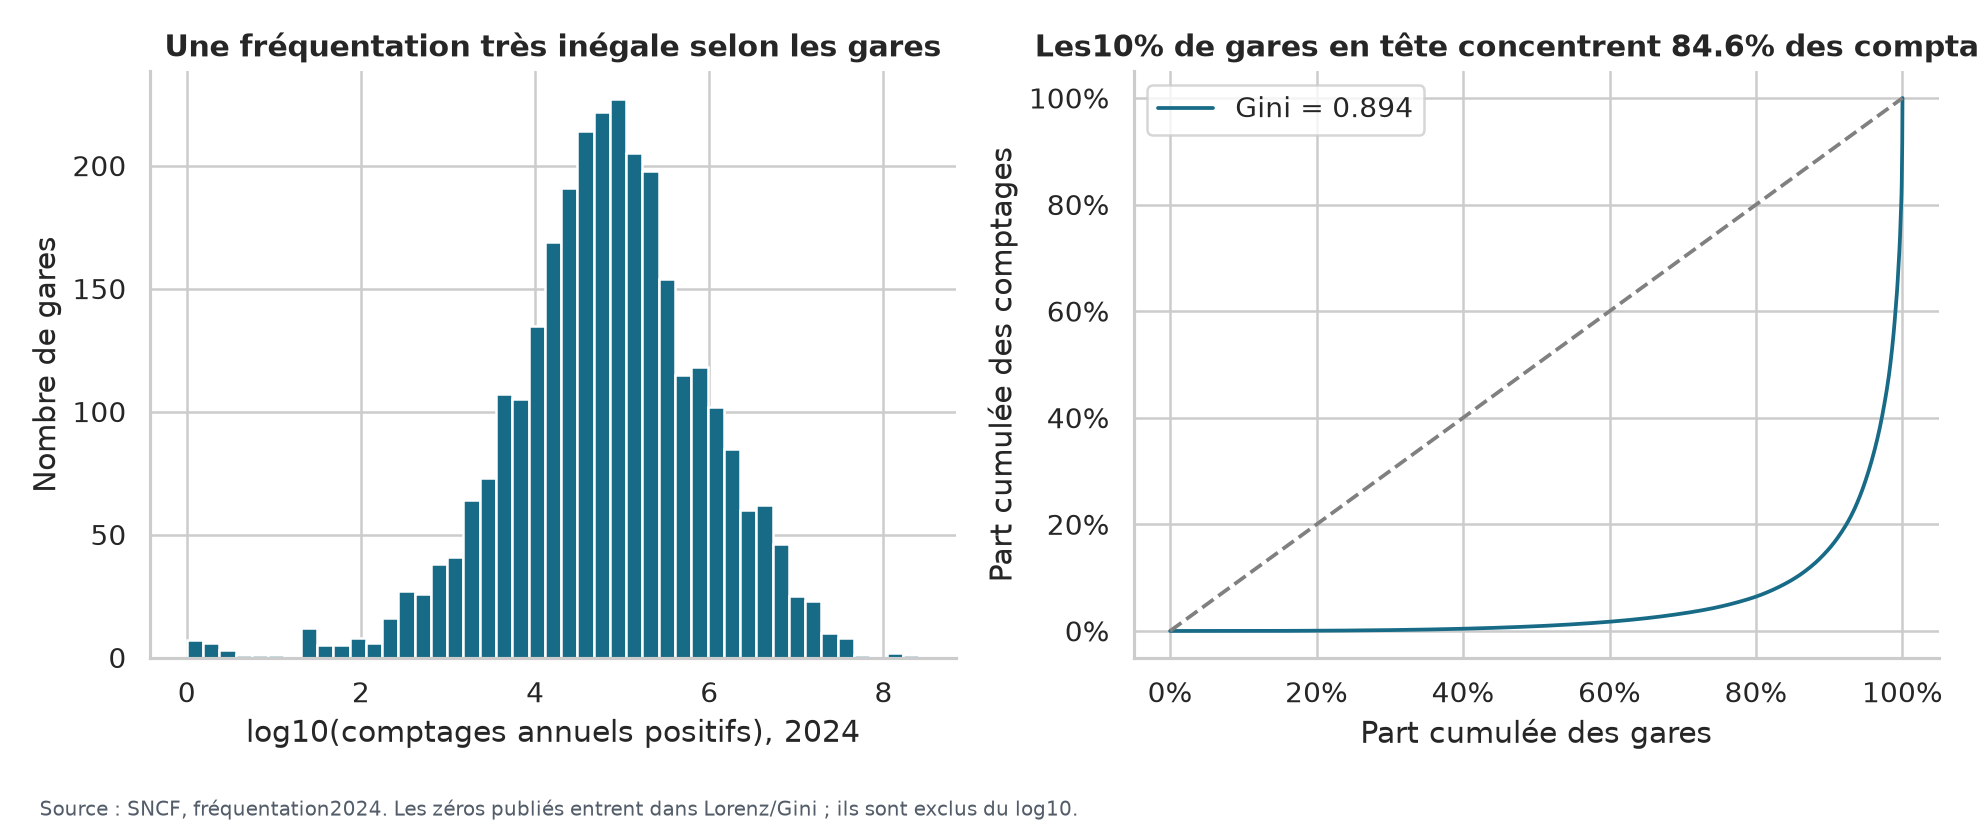

In [4]:
display(pd.read_csv('outputs/tables/frequentation_annuelle.csv'))
display(pd.read_csv('outputs/tables/distribution_gares_2024.csv'))
display(Image(filename='outputs/figures/01_evolution_rail.png', width=900))
display(Image(filename='outputs/figures/02_concentration.png', width=950))

## 4. Le rail et la population évoluent-ils ensemble ?

La cohorte comporte les mêmes UIC aux deux dates : comptage2016strictement positif,2022observé, y compris zéro. Les nouvelles gares et bases nulles ne sont donc pas représentées par ce taux. Les alertes géographiques INSEE sont exclues du croisement principal.

L'échantillon est constitué de communes d'implantation de gares observées ; ce n'est pas un tirage représentatif des communes françaises. Les taux comparent une population résidente à un usage dont le bassin peut dépasser largement la commune.

,communes,part_population_metropole_pct,Pearson,Spearman,population_hausse_rail_baisse
0,2618,46.760691,0.111116,0.114349,484


,champ,n_communes,pearson,spearman
0,communes avec cohorte,2618,0.111116,0.114349
1,hors Île-de-France,2345,0.120405,0.157486
2,comptages2016 au moins10000,1909,0.118738,0.086601
3,hors1% des comptages2022 les plus élevés,2591,0.111683,0.116204
4,incluant les alertes géographiques INSEE,2623,0.110876,0.114253


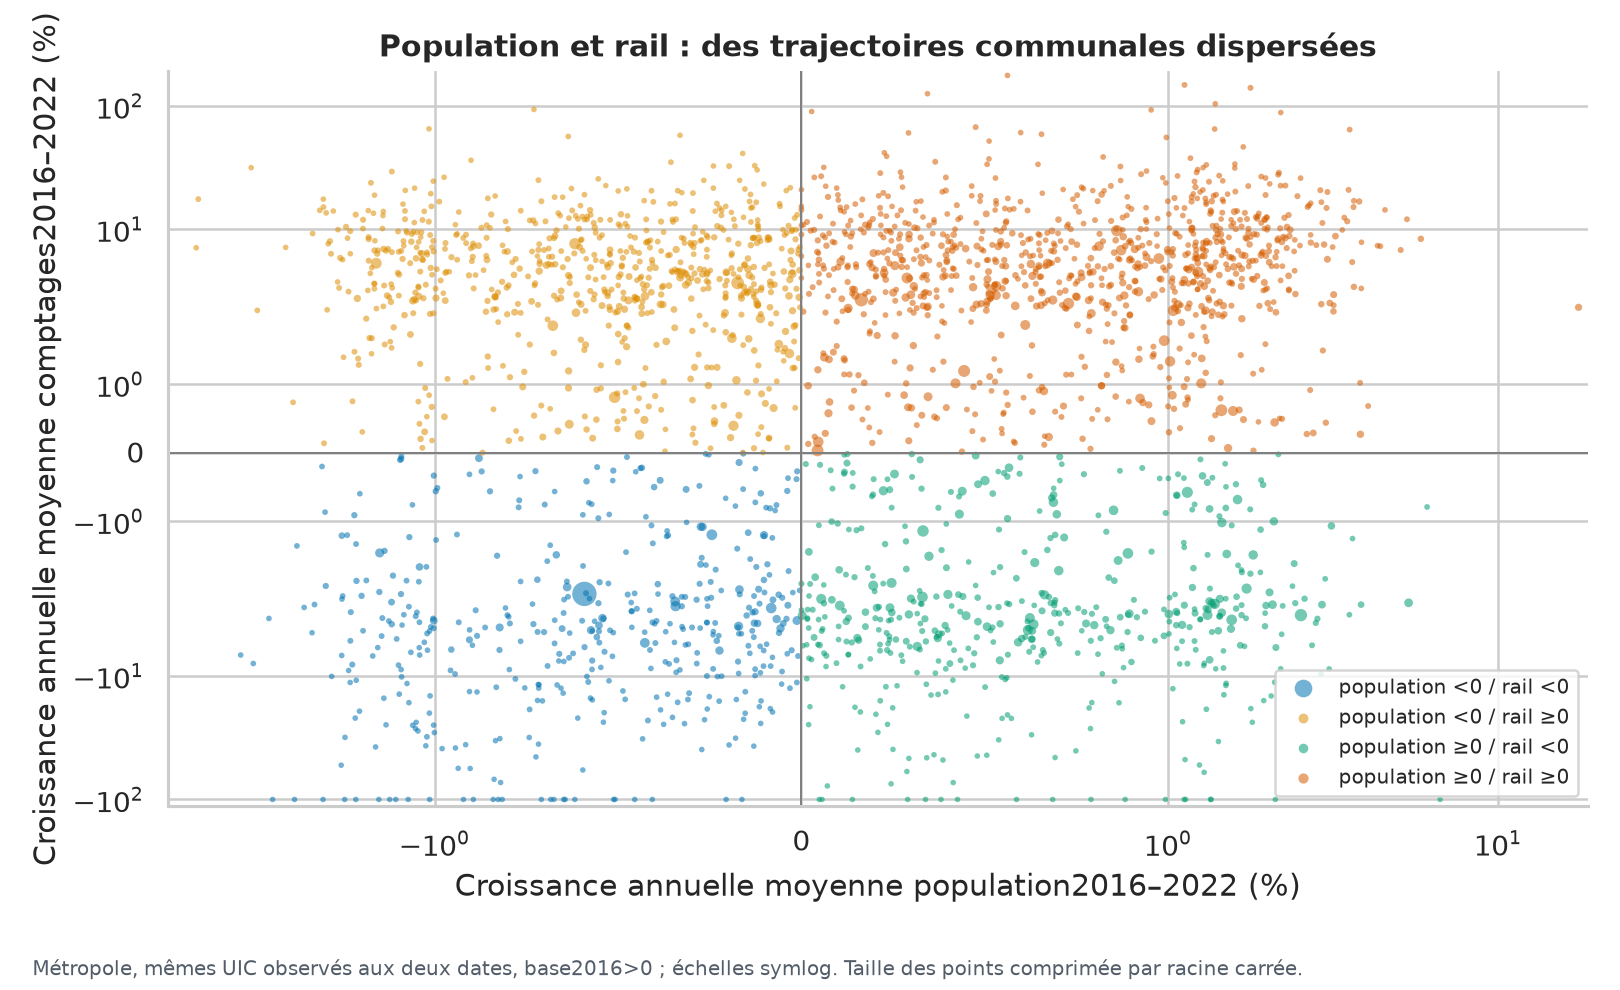

In [5]:
principal = communes[communes.metropole
                     & communes.tcam_rail_2016_2022_pct.notna()
                     & communes.tcam_population_2016_2022_pct.notna()
                     & ~communes.alerte_comparabilite_rail_population].copy()
x = principal.tcam_population_2016_2022_pct
y = principal.tcam_rail_2016_2022_pct
part_population = 100 * principal.population_2022.sum() / communes.loc[communes.metropole, 'population_2022'].sum()
display(pd.DataFrame([{'communes': len(principal), 'part_population_metropole_pct': part_population,
                      'Pearson': x.corr(y), 'Spearman': x.corr(y, method='spearman'),
                      'population_hausse_rail_baisse': int(((x > 0) & (y < 0)).sum())}]))
display(pd.read_csv('outputs/tables/sensibilite_correlations.csv'))
display(Image(filename='outputs/figures/03_rail_population.png', width=950))

Les associations calculées sont faibles dans les variantes étudiées. Elles ne mesurent ni l'adéquation de l'offre ni l'effet de la population sur l'usage ferroviaire. Les quadrants classent des signes ; les taux nuls figurent dans≥0.

## 5. Mobilité automobile, densité et variation de la part voiture

Les parts sont calculées comme ratios des effectifs agrégés sur le même ensemble de communes valides. La population de référence est celle des actifs occupés de15ansou plus, y compris les personnes sans déplacement. La catégorie INSEE « transports en commun » ne se réduit pas au train. Les corrélations n'identifient pas un report modal.

,classe_densite,n_communes,population_2022,part_modale_voiture_2022_pct,distance_centre_gare_km_mediane,population_proxy_plus10km_pct
0,Rural,30540,21602515,86.177462,9.003127,35.794047
1,Urbain dense,692,24773574,47.259731,1.852223,0.132597
2,Urbain intermédiaire,3514,19470166,78.741101,3.078572,6.847280


,n_communes,pearson,spearman
0,2618,-0.035099,-0.034418


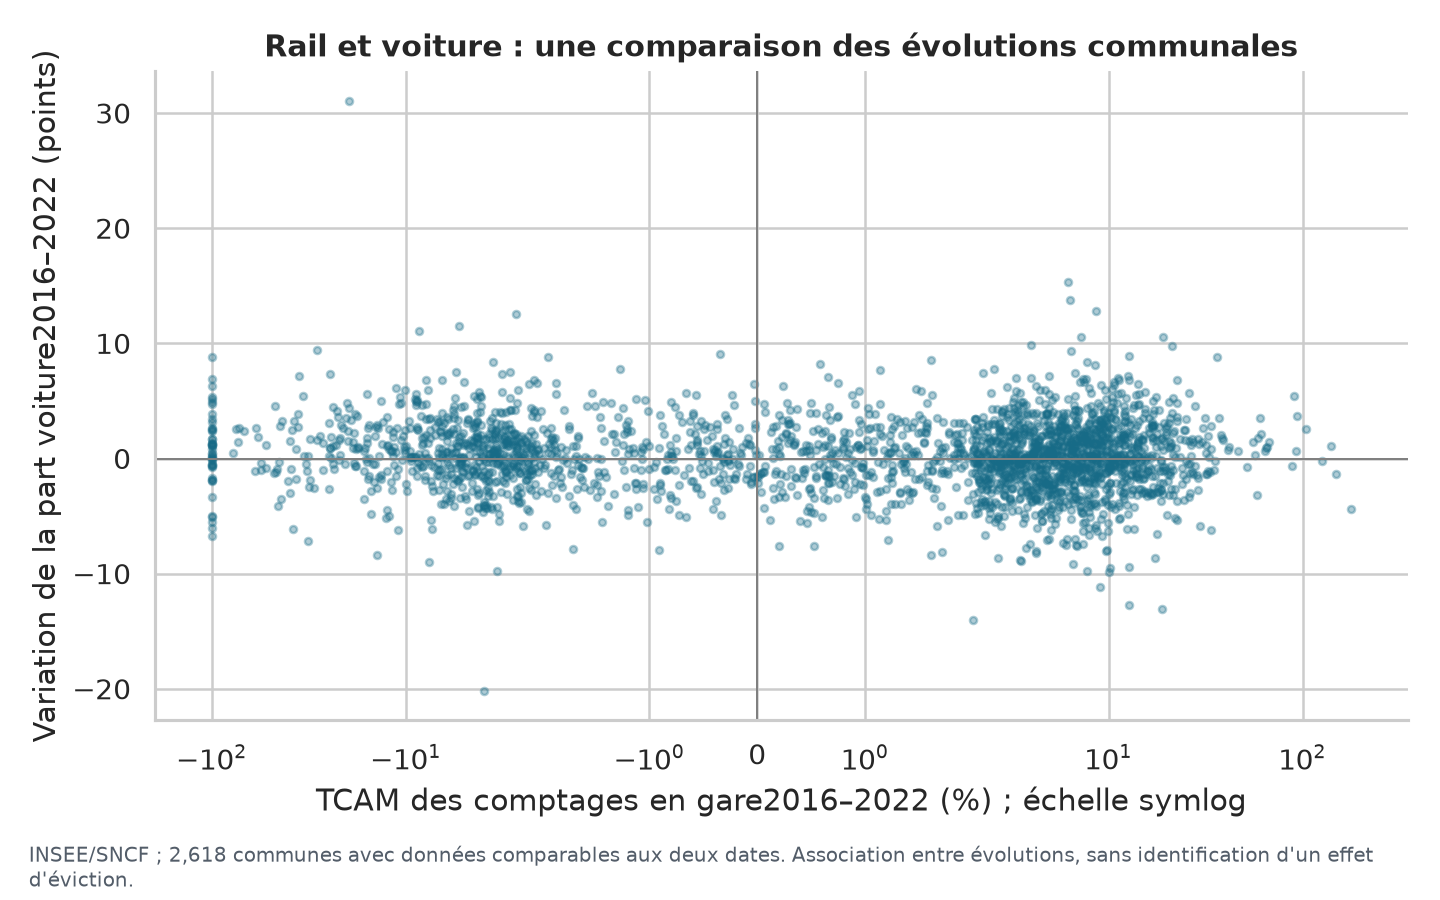

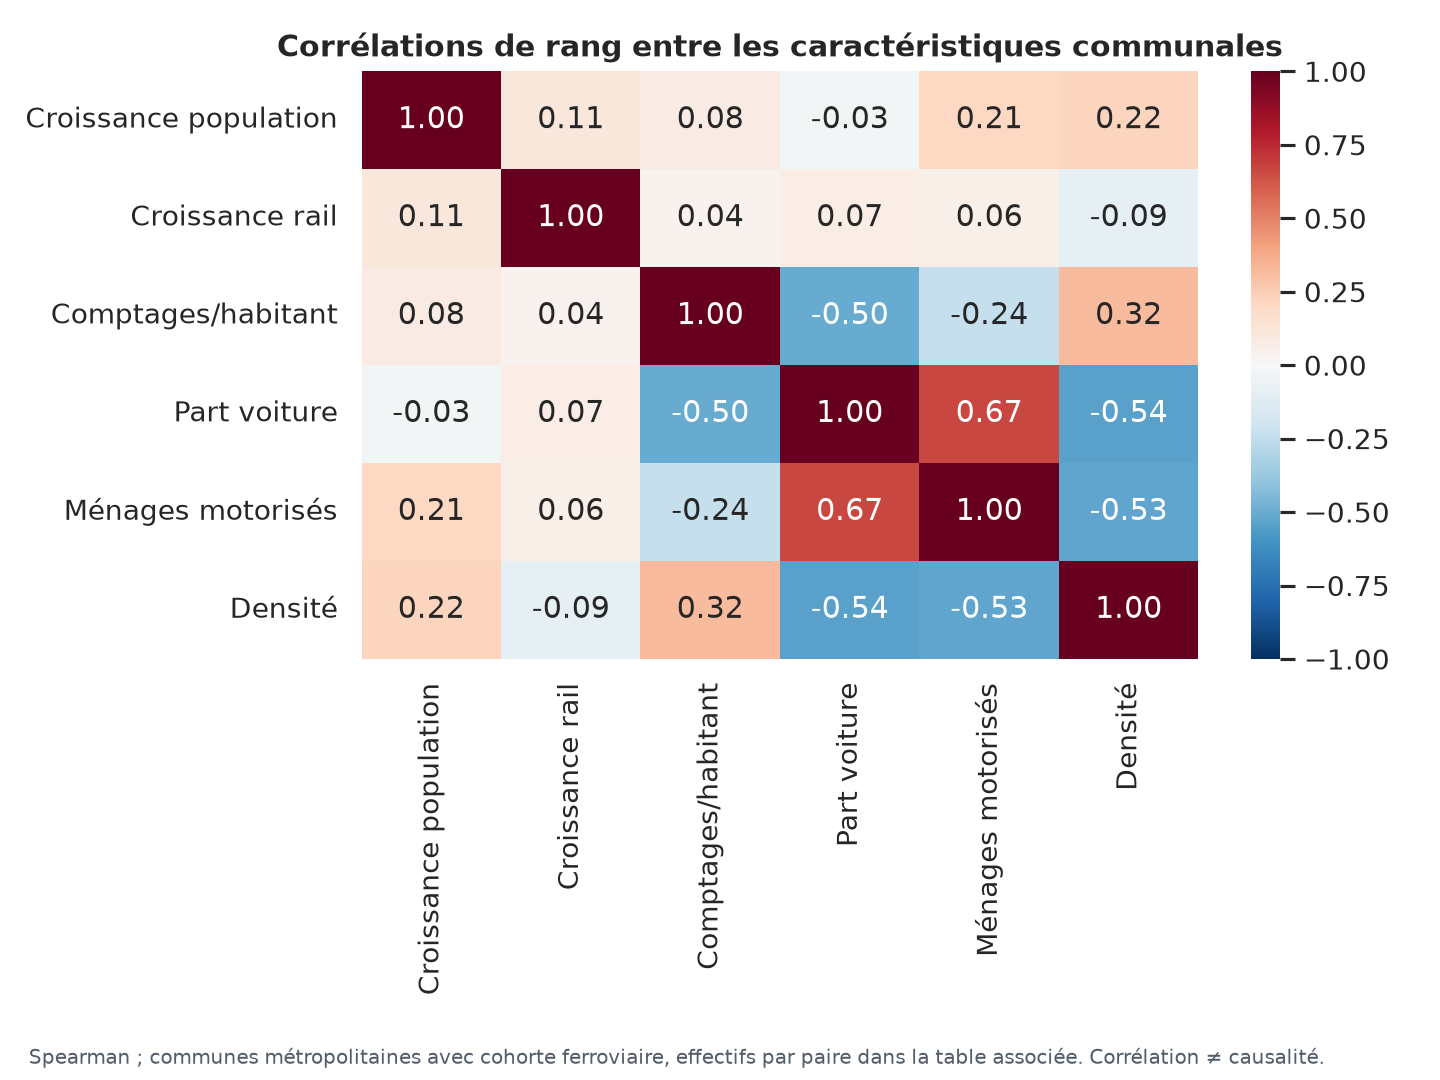

In [6]:
display(pd.read_csv('outputs/tables/mobilites_par_densite.csv'))
display(pd.read_csv('outputs/tables/correlation_rail_evolution_voiture.csv'))
display(Image(filename='outputs/figures/11_rail_evolution_voiture.png', width=900))
display(Image(filename='outputs/figures/05_correlations.png', width=850))

## 6. Éloignement des gares SNCF : portée du proxy

La distance relie le **centroïde géométrique** communal à une gare du fichier SNCF avec comptage positif en2024. La Corse est hors champ et laissée manquante ; la source ne couvre pas tous les réseaux ferrés, notamment RATP et Chemins de fer de Provence. Ce n'est ni une distance individuelle, ni un temps d'accès, ni une mesure de desserte.

La pondération affecte tous les habitants d'une commune au classement de son centroïde. La « croissance positive » est la somme des hausses communales écrêtées à zéro, et non la croissance nette.

,seuil_km,nb_communes,population_communes_concernees_2022,population_champ_2022,part_population_proxy_pct,croissance_positive_concernee,part_croissance_positive_proxy_pct
0,5,24268,19596023,65494979,29.919886,668653,30.867499
1,10,13670,9036258,65494979,13.796871,252467,11.654812
2,15,7282,4409202,65494979,6.732122,107143,4.946118


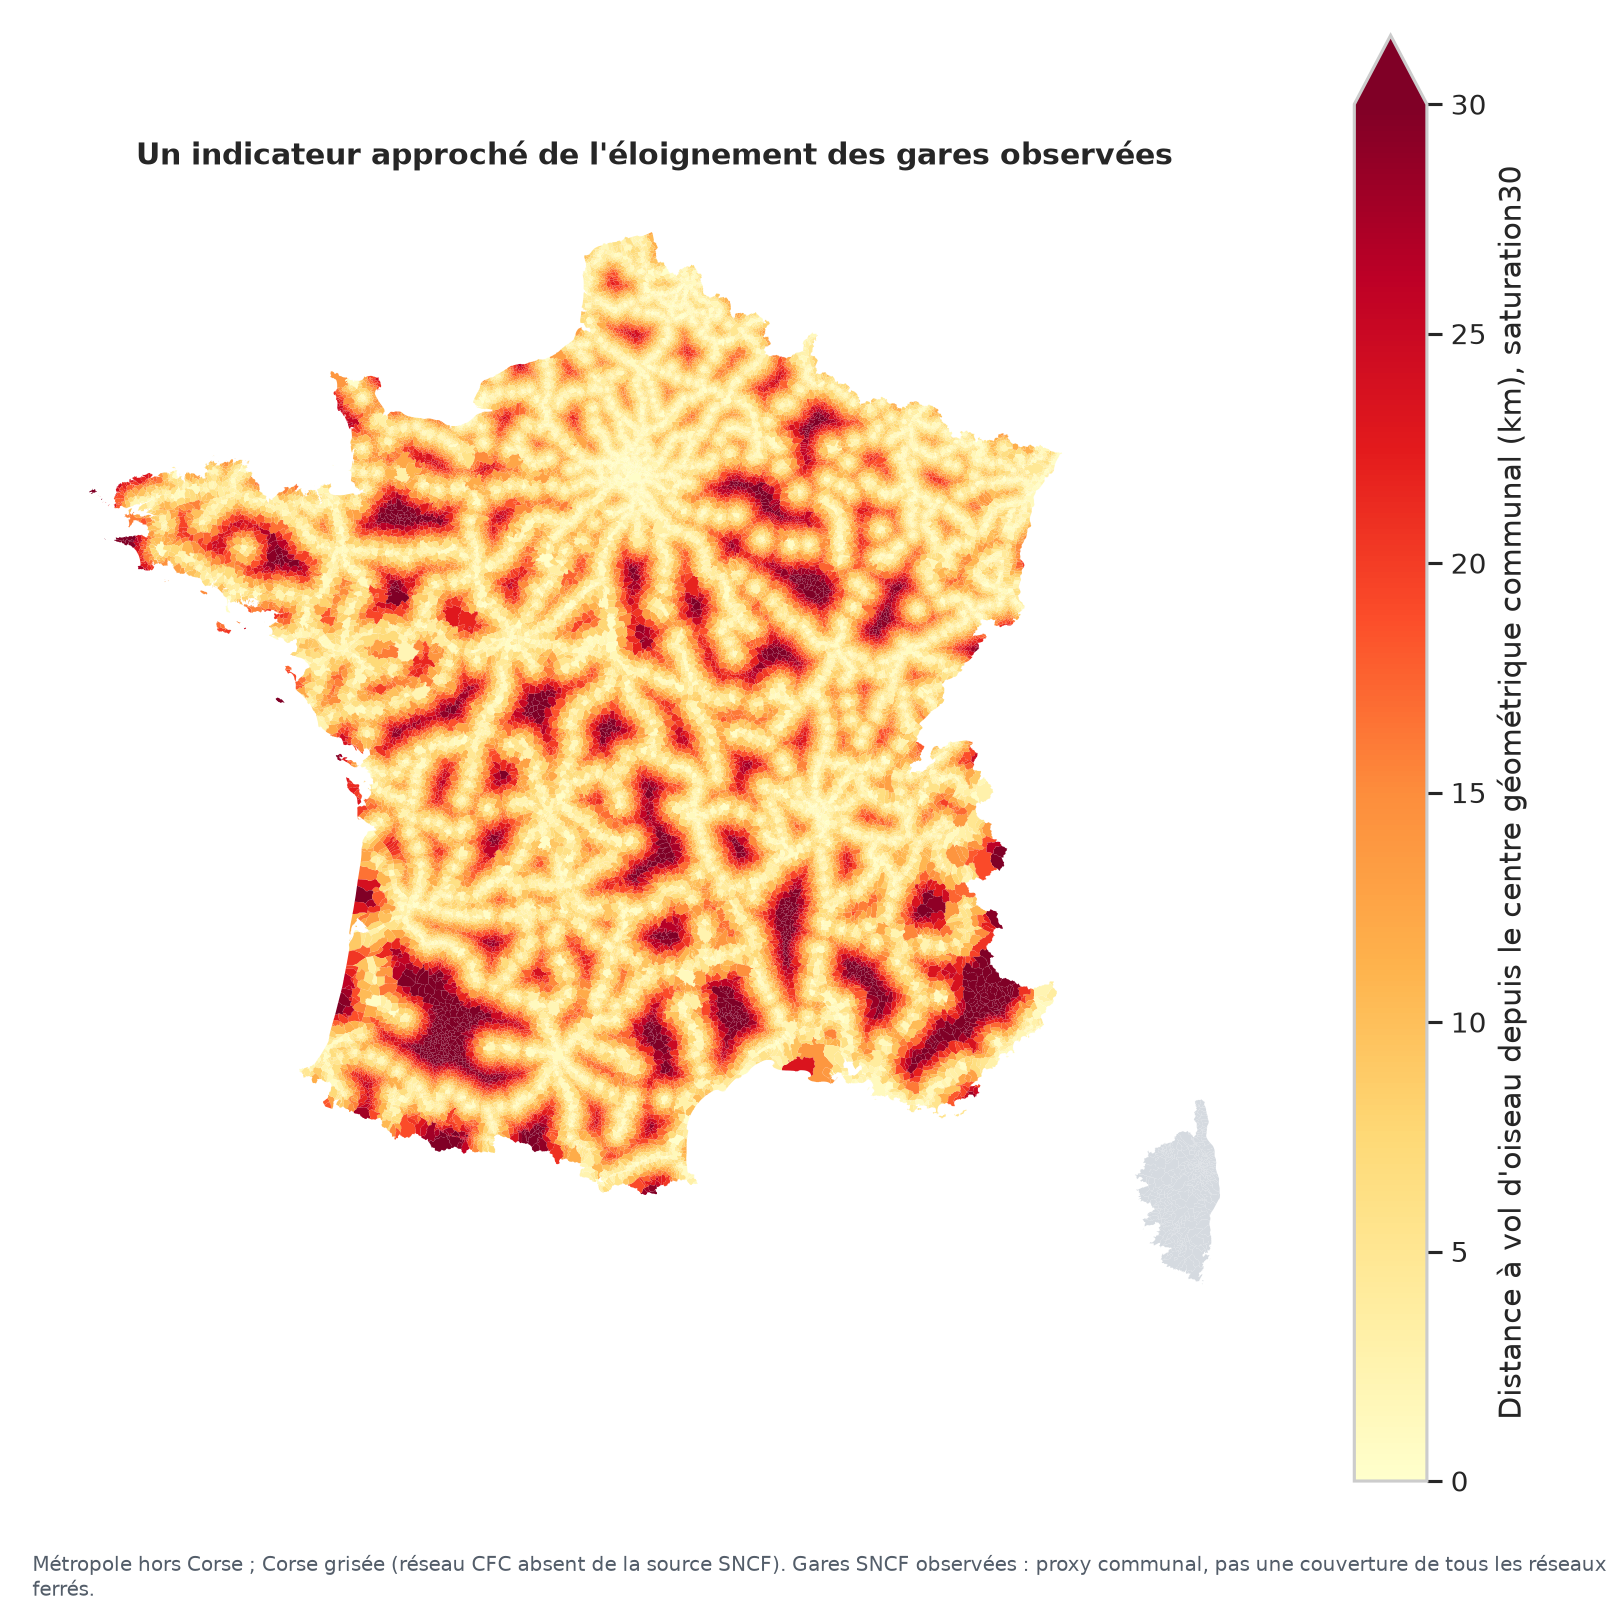

In [7]:
display(pd.read_csv('outputs/tables/accessibilite_proxy.csv'))
display(Image(filename='outputs/figures/09_carte_distance.png', width=850))

## 7. Climat et scénarios de population

Le parc de voitures est un stock ; il ne mesure pas les émissions routières d'une commune. Les facteurs ADEME sont des références enCO₂epar voyageur.km, construction incluse et voiture à un occupant. Sans distances, origines–destinations et report observé, aucun total d'émissions évitées n'est calculé.

Les projections Omphale sont des scénarios INSEE départementaux, base2018. Les variantes bas/haut ne sont pas des intervalles de confiance et ne sont pas transformées en prévision de trafic.

,id_mode_ademe,mode,kgco2e_par_voyageur_km,gco2e_par_voyageur_km,perimetre,date_collecte
0,2,TGV,0.002930,2.930000,API Impact CO2 includeConstruction=1; taux voi...,2026-10-26T15:18:14.407593+00:00
1,3,Intercités,0.008980,8.980000,API Impact CO2 includeConstruction=1; taux voi...,2026-10-26T15:18:14.407593+00:00
2,4,Voiture thermique,0.142253,142.253412,API Impact CO2 includeConstruction=1; taux voi...,2026-10-26T15:18:14.407593+00:00
3,5,Voiture électrique,0.067365,67.365262,API Impact CO2 includeConstruction=1; taux voi...,2026-10-26T15:18:14.407593+00:00
4,14,RER ou Transilien,0.009780,9.780000,API Impact CO2 includeConstruction=1; taux voi...,2026-10-26T15:18:14.407593+00:00
5,15,TER,0.027690,27.690000,API Impact CO2 includeConstruction=1; taux voi...,2026-10-26T15:18:14.407593+00:00


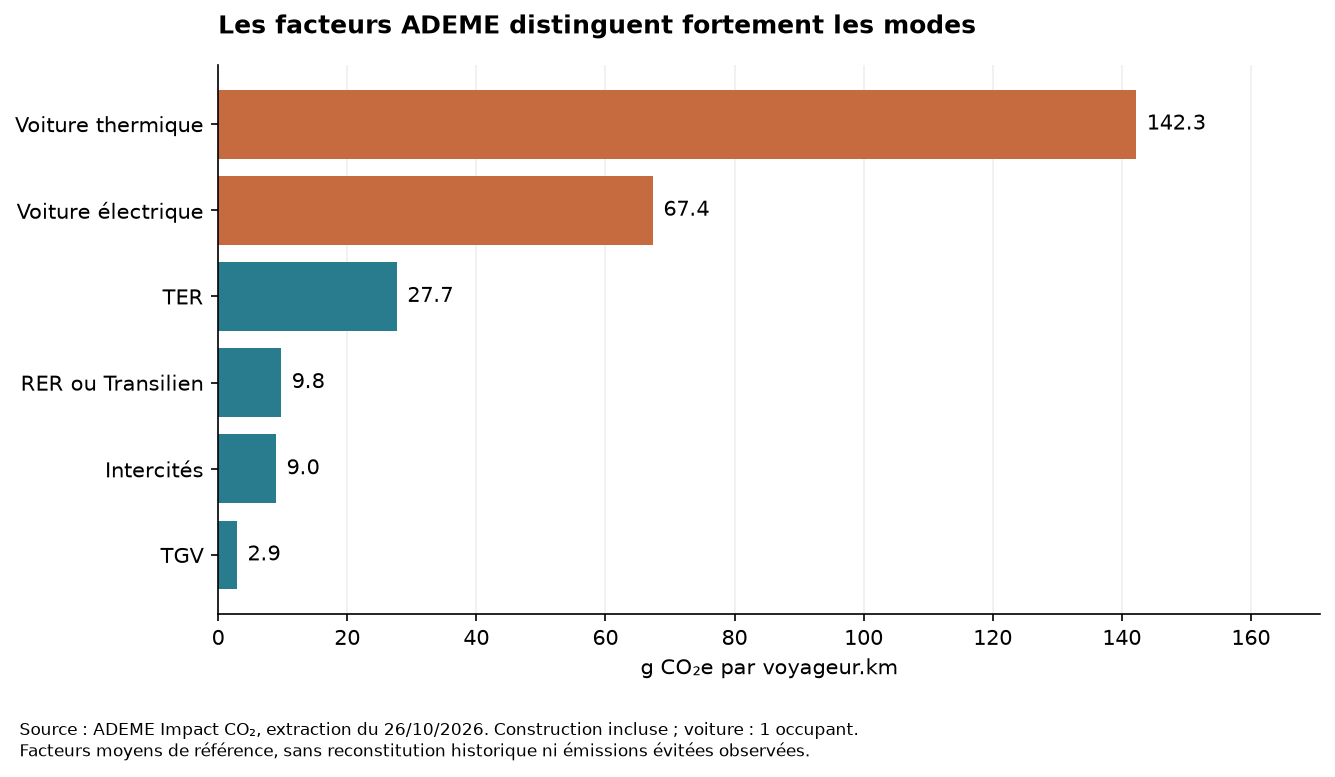

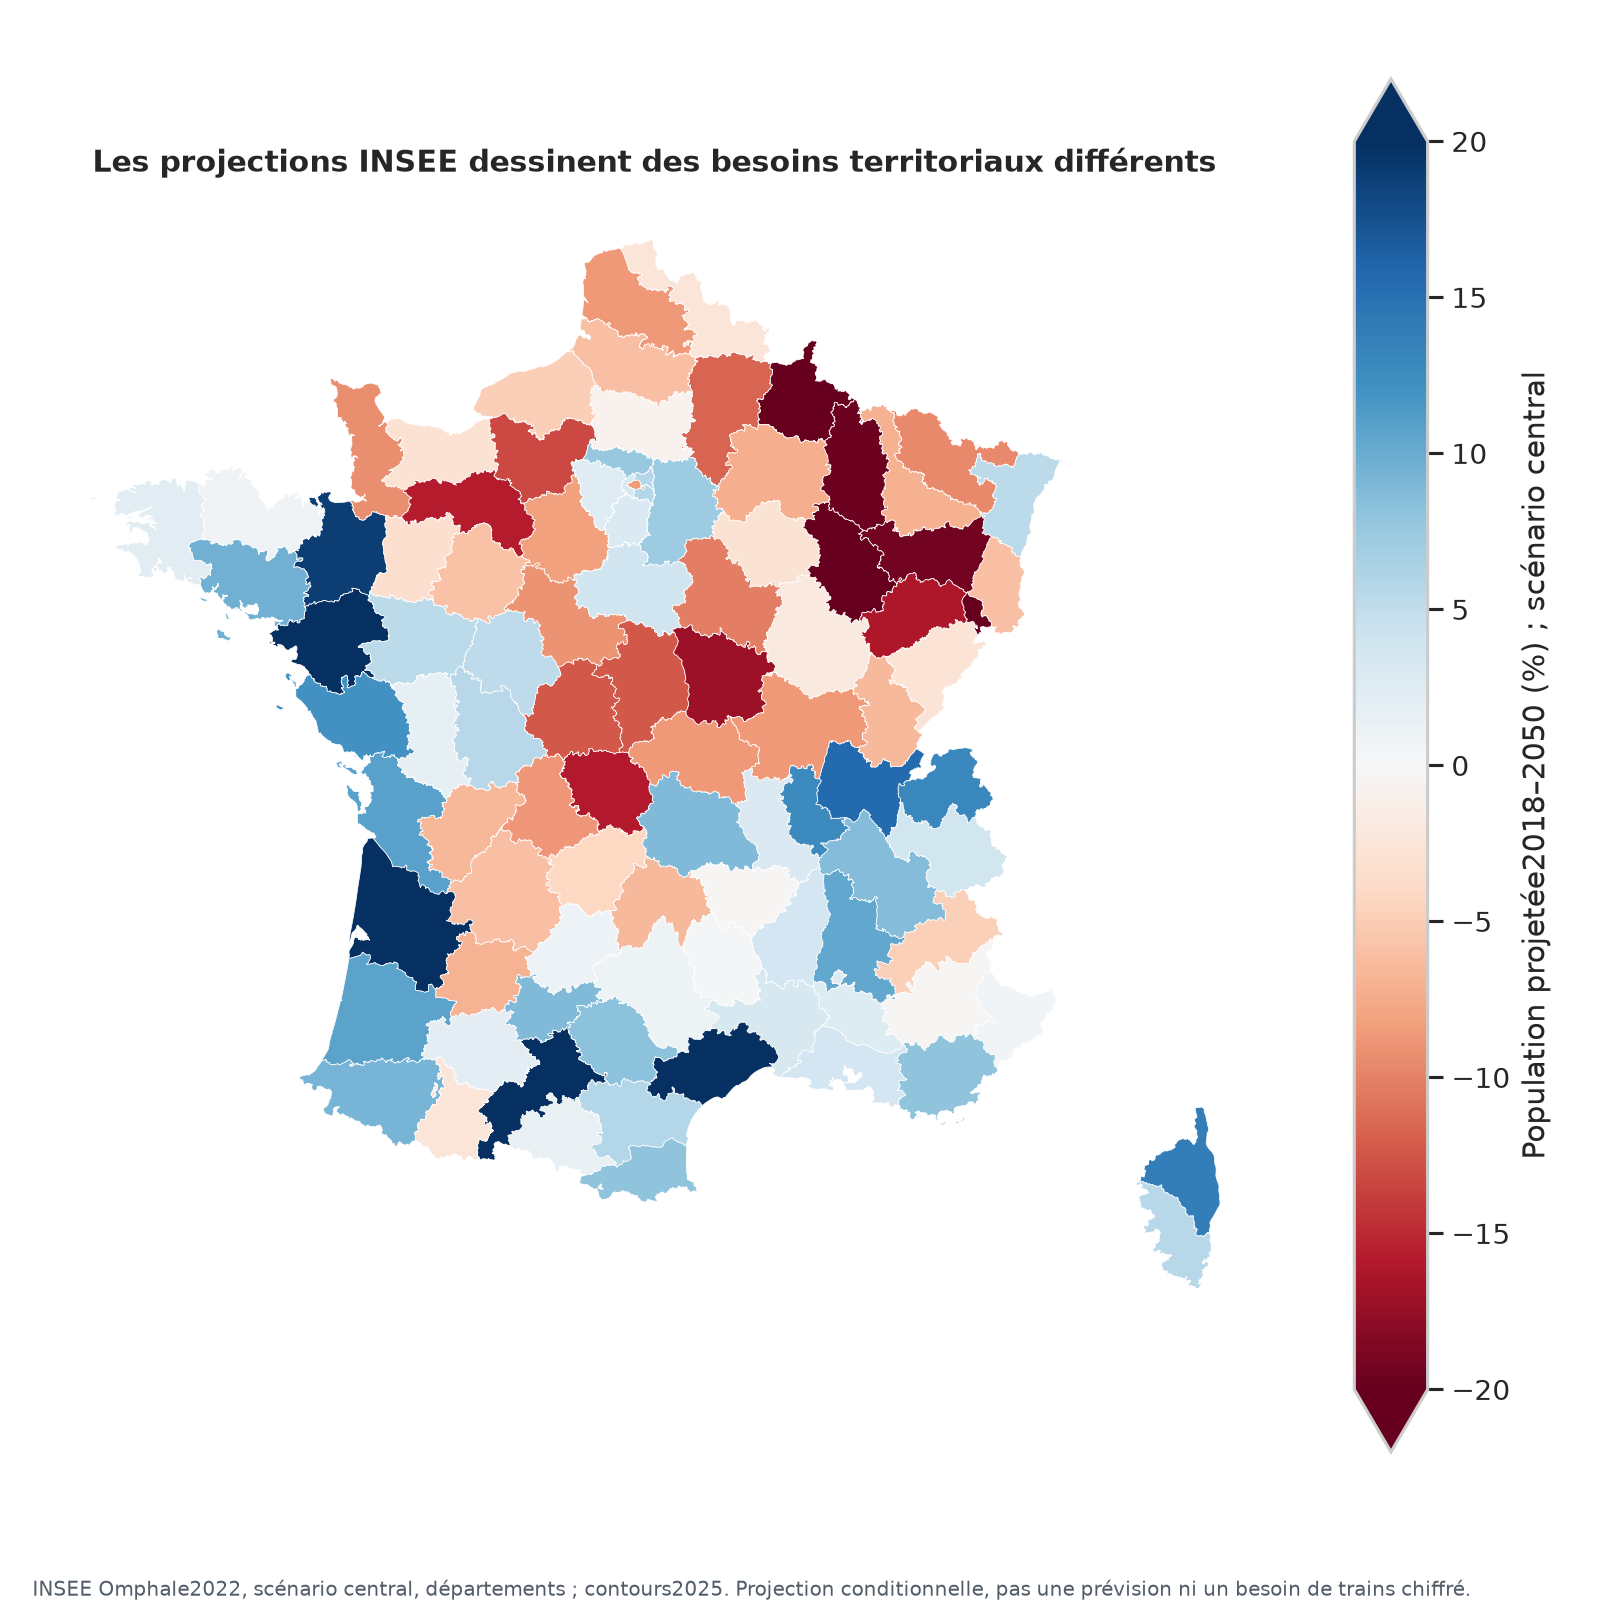

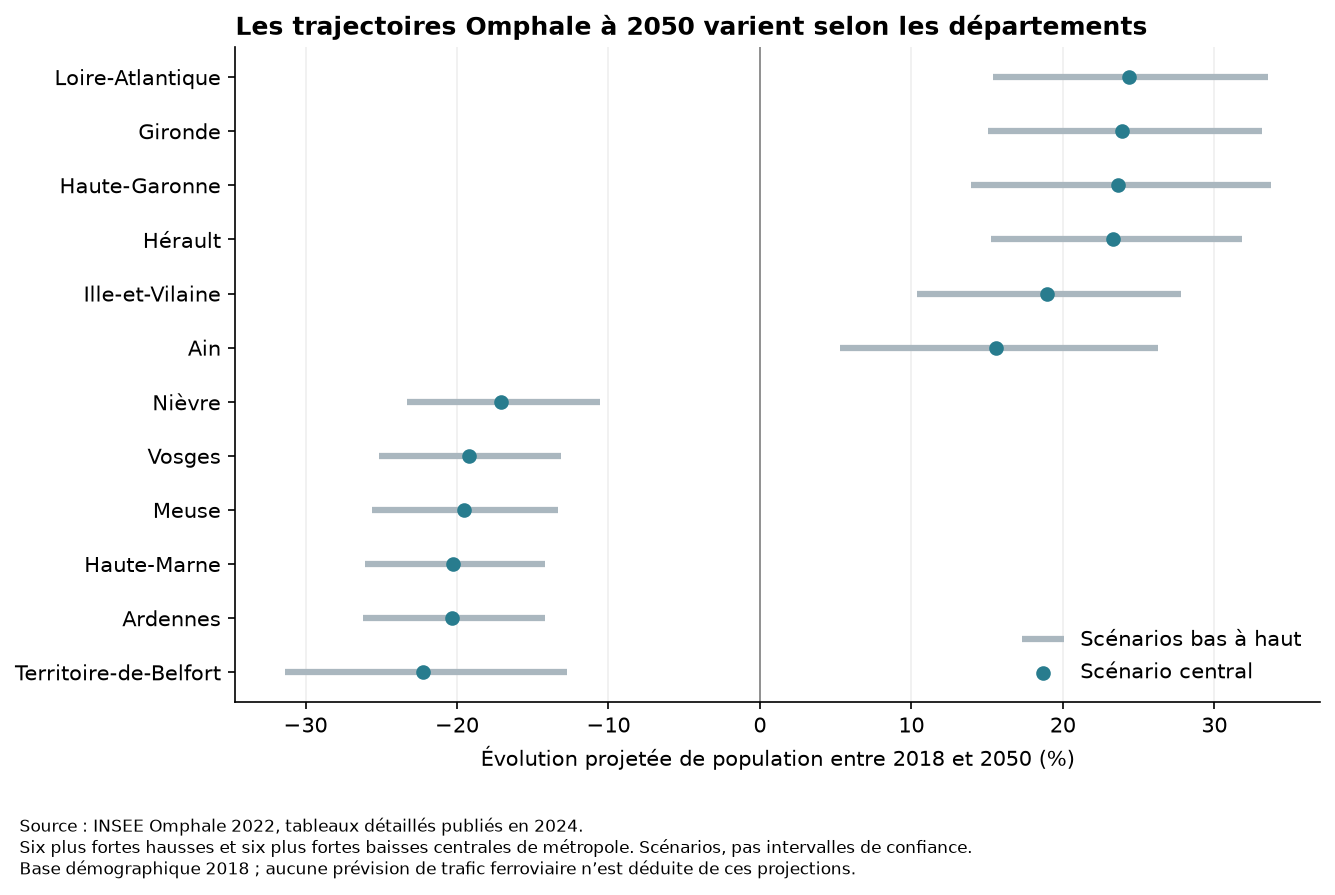

In [8]:
display(pd.read_parquet('data/processed/climat_facteurs_ademe.parquet'))
display(Image(filename='outputs/climat/facteurs_ademe.png', width=850))
display(Image(filename='outputs/figures/10_carte_projections.png', width=850))
display(Image(filename='outputs/climat/projections_2050.png', width=850))

## 8. Avion : complément descriptif et censure des liaisons

La tendance intérieure métropolitaine repose sur LSN, agrégée. PAP est censurée par secret statistique et seuils : une absence n'est jamais un zéro et les deux sens déjà réunis ne sont pas doublés. Les unités DGAC et les comptages SNCF diffèrent ; leur comparaison ne mesure pas un report avion–train ni l'effet du décret2023-385.

,annee,LSN_FSC,passagers,dessertes,mois_observes,passagers_2019,indice_2019_100
0,2015,MET_INTERIEUR,24019649,307846,12,26753422,89.781595
1,2016,MET_INTERIEUR,24776730,307811,12,26753422,92.611442
2,2017,MET_INTERIEUR,25606136,308848,12,26753422,95.711629
3,2018,MET_INTERIEUR,26210825,308788,12,26753422,97.971859
4,2019,MET_INTERIEUR,26753422,305510,12,26753422,100.000000
5,2020,MET_INTERIEUR,11566114,154025,12,26753422,43.232279
6,2021,MET_INTERIEUR,15755474,196840,12,26753422,58.891435
7,2022,MET_INTERIEUR,22581828,246288,12,26753422,84.407251
8,2023,MET_INTERIEUR,21242764,224958,12,26753422,79.402044
9,2024,MET_INTERIEUR,20160921,209118,12,26753422,75.358289


,annee,liaisons_publiees,passagers_pap_observes,liaisons_12_mois,passagers,ratio_pap_sur_lsn_pct
0,2015,34,8202785,7,24019649,34.150312
1,2016,40,8844976,7,24776730,35.698722
2,2017,41,10508302,10,25606136,41.038218
3,2018,47,13103179,13,26210825,49.991479
4,2019,50,12269572,9,26753422,45.861692
5,2020,31,3226738,0,11566114,27.898203
6,2021,45,5654481,4,15755474,35.888993
7,2022,37,7179954,5,22581828,31.795274
8,2023,39,7583682,5,21242764,35.700072
9,2024,28,6411765,2,20160921,31.802937


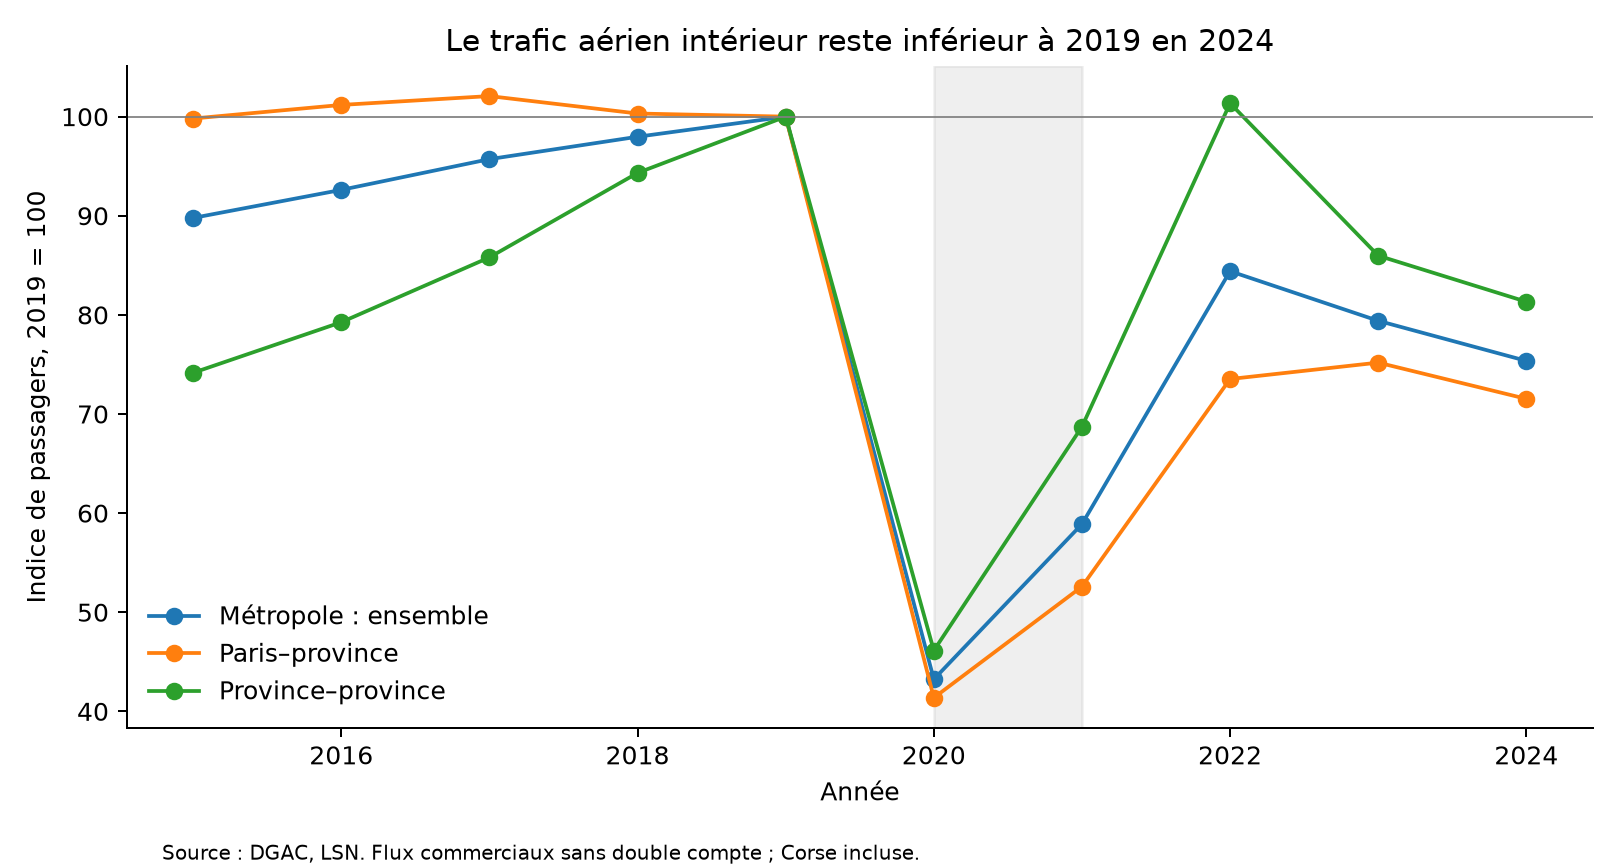

,ligne,mise_en_service_brute,date_exacte_iso_si_disponible,url_source
0,LGV Sud Europe Atlantique,2 juillet 2017,2017-07-02,https://fr.wikipedia.org/wiki/LGV_Sud_Europe_A...
1,LGV Bretagne-Pays de la Loire,2 juillet 2017,2017-07-02,https://fr.wikipedia.org/wiki/LGV_Bretagne-Pay...
2,LGV Atlantique,1989 – 1990,NaN,https://fr.wikipedia.org/wiki/LGV_Atlantique


In [9]:
display(pd.read_csv('outputs/aviation/trafic_metropole_2015_2024.csv'))
display(pd.read_csv('outputs/aviation/couverture_pap_metropole.csv'))
display(Image(filename='outputs/aviation/trafic_aerien_base100.png', width=850))
display(pd.read_csv('data/processed/contexte_lgv.csv')[['ligne', 'mise_en_service_brute', 'date_exacte_iso_si_disponible', 'url_source']])

## 9. Validation et restitution

L'audit contrôle les empreintes, les clés, les sommes, les ratios et les champs. Il ne remplace pas les notices ni un contrôle indépendant chez les producteurs. Les limites majeures sont la sélection des communes avec gare, les bassins de desserte non mesurés, les révisions de comptage et la censure aérienne.

Les documents finaux sont [le rapport](docs/RAPPORT_ANALYSE.html), [la méthodologie](docs/METHODOLOGIE.html) et [le support de soutenance](docs/SOUTENANCE.md).

In [10]:
validation_finale = valider()
display(pd.DataFrame([{k: validation_finale[k] for k in ['statut', 'nombre_controles', 'nombre_echecs']}]))
assert validation_finale['statut'] == 'CONFORME'
print('Reconstruction et analyse terminées sans erreur à partir des archives brutes.')

,statut,nombre_controles,nombre_echecs
0,CONFORME,72,0


Reconstruction et analyse terminées sans erreur à partir des archives brutes.
